# 02 · Representación neuronal de una imagen y codificación posicional

**Curso:** Fundamentos de Programación para la Inteligencia Artificial · **Autor:** William Lu Bjornestad

---

En el cuaderno anterior una red aprendía funciones $\mathbb{R} \to \mathbb{R}^3$. Aquí la función a aprender es **una imagen**: un MLP recibe las coordenadas $(x, y)$ de un píxel y devuelve su color $(R, G, B)$. Esta idea, conocida como *representación neuronal implícita*, es la base de técnicas como NeRF.

Como la red representa la imagen como una función continua, se puede evaluar en coordenadas que no estaban en la imagen original y generar una versión de **mayor resolución**.

**Objetivos**

- Reducir la imagen de referencia a $35 \times 30$ píxeles y entrenar un MLP que la reconstruya.
- Generar la imagen a doble resolución ($70 \times 60$) evaluando la red en una malla más fina.
- Entender por qué aparecen artefactos al aumentar la resolución y cómo corregirlos.

**Conceptos de pipeline de ML introducidos**

| Etapa | Qué se ve en este cuaderno |
|---|---|
| `Dataset` personalizado | Clase propia que empareja coordenadas y colores |
| Ingeniería de características | Codificación posicional de la entrada |
| Validación sobre datos no vistos | 10 % de los píxeles reservados para medir interpolación |
| Seguimiento de experimentos | Barrido de hiperparámetros con tabla de resultados |
| Reentrenamiento final | Tras elegir la configuración, se entrena con todos los datos |

In [1]:
import copy
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from torchvision.io import ImageReadMode, read_image
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


## 1. Preparación de la imagen

La imagen se reduce a $35 \times 30$ y sus píxeles se normalizan a $[0, 1]$ dividiendo entre 255. Esta versión reducida es la referencia (*ground truth*) durante todo el cuaderno. Se reorganiza como una tabla de $35 \cdot 30 = 1050$ filas con los tres canales de color.

Imagen original: (700, 600) -> reducida: (35, 30)
Tabla de píxeles: (1050, 3)


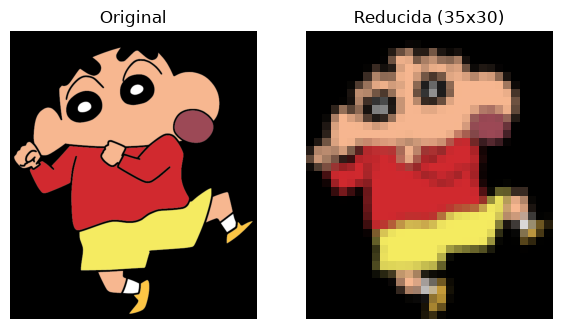

In [2]:
IMG_PATH = "../assets/shin_chan_progIA.png"
IMG_H, IMG_W = 35, 30

image_full = read_image(IMG_PATH, mode=ImageReadMode.RGB).float() / 255.0          # (C, H, W)
image_small = transforms.Resize((IMG_H, IMG_W), antialias=True)(image_full)
pixels = image_small.permute(1, 2, 0).reshape(-1, 3)                               # (H*W, 3)

print(f"Imagen original: {tuple(image_full.shape[1:])} -> reducida: {tuple(image_small.shape[1:])}")
print(f"Tabla de píxeles: {tuple(pixels.shape)}")

fig, axes = plt.subplots(1, 2, figsize=(7, 4))
axes[0].imshow(image_full.permute(1, 2, 0))
axes[0].set_title("Original")
axes[1].imshow(image_small.permute(1, 2, 0))
axes[1].set_title(f"Reducida ({IMG_H}x{IMG_W})")
for ax in axes:
    ax.axis("off")
plt.show()

## 2. Coordenadas y `Dataset` personalizado

Cada píxel se describe por sus coordenadas normalizadas en $[0, 1]$. La misma función `make_grid` sirve para la resolución original y para cualquier otra: la red nunca "ve" índices de píxel, solo posiciones continuas.

In [3]:
def make_grid(h, w):
    ys = torch.linspace(0, 1, h)
    xs = torch.linspace(0, 1, w)
    grid_y, grid_x = torch.meshgrid(ys, xs, indexing="ij")
    return torch.stack([grid_x, grid_y], dim=-1).reshape(-1, 2)   # (h*w, 2) con orden (x, y)


class ImageDataset(Dataset):
    def __init__(self, coords, colors):
        self.coords = coords
        self.colors = colors

    def __len__(self):
        return self.coords.shape[0]

    def __getitem__(self, idx):
        return self.coords[idx], self.colors[idx]


coords = make_grid(IMG_H, IMG_W)
dataset = ImageDataset(coords.to(device), pixels.to(device))

Se reserva un 10 % de los píxeles como **validación**. Estos píxeles nunca se usan para entrenar, así que su error mide lo mismo que interesa al subir la resolución: cómo de bien predice la red el color en posiciones que no ha visto. La partición es reproducible gracias a un generador con semilla.

In [4]:
VAL_SPLIT = 0.1
BATCH_SIZE = 32

n_val = int(len(dataset) * VAL_SPLIT)
train_set, val_set = random_split(
    dataset, [len(dataset) - n_val, n_val], generator=torch.Generator().manual_seed(SEED)
)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)
print(f"Píxeles de entrenamiento: {len(train_set)} | validación: {len(val_set)}")

Píxeles de entrenamiento: 945 | validación: 105


## 3. Codificación posicional

Los MLP con ReLU tienen **sesgo espectral** (*spectral bias*): aprenden con facilidad funciones suaves y con mucha dificultad los cambios bruscos, como los bordes de una imagen. La codificación posicional proyecta cada coordenada $p$ sobre senos y cosenos de frecuencias crecientes:

$$\gamma(p) = \big(p,\ \sin(2^0\pi p),\ \cos(2^0\pi p),\ \dots,\ \sin(2^{L-1}\pi p),\ \cos(2^{L-1}\pi p)\big)$$

Con estas características, un cambio brusco del color se puede expresar como combinación de funciones de alta frecuencia que la red ya recibe hechas. Para una entrada 2D, la dimensión resultante es $2 + 2 \cdot 2 \cdot L$ (42 con $L = 10$).

El número de bandas $L$ es un **hiperparámetro de preprocesado**, no del modelo, y va a resultar decisivo.

In [5]:
class PositionalEncoder(nn.Module):
    def __init__(self, n_freqs=10, include_input=True):
        super().__init__()
        self.include_input = include_input
        # register_buffer hace que las frecuencias se muevan con el modelo al llamar a .to(device)
        self.register_buffer("freq_bands", 2.0 ** torch.arange(n_freqs, dtype=torch.float32))

    def forward(self, x):
        out = [x] if self.include_input else []
        for freq in self.freq_bands:
            out.append(torch.sin(freq * math.pi * x))
            out.append(torch.cos(freq * math.pi * x))
        return torch.cat(out, dim=-1)

    def output_dim(self, input_dim):
        return input_dim * (int(self.include_input) + 2 * len(self.freq_bands))


class ImageMLP(nn.Module):
    def __init__(self, n_freqs=10, hidden=256):
        super().__init__()
        self.encoder = PositionalEncoder(n_freqs)
        self.mlp = nn.Sequential(
            nn.Linear(self.encoder.output_dim(2), hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 3),
            nn.Sigmoid(),   # colores acotados en [0, 1]
        )

    def forward(self, x):
        return self.mlp(self.encoder(x))

## 4. Bucle de entrenamiento

Es el mismo esquema del cuaderno 01 (entrenamiento, validación y *checkpoint* del mejor modelo), ahora independiente del dispositivo. Además de la pérdida L1 se reporta el **PSNR** (*peak signal-to-noise ratio*) de validación, la métrica estándar de calidad de imagen: $\text{PSNR} = 10 \log_{10}(1 / \text{MSE})$ para píxeles en $[0, 1]$. Más alto es mejor, y cada 6 dB equivalen aproximadamente a reducir el error cuadrático a la cuarta parte.

In [6]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total = 0.0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * xb.size(0)
    return total / len(loader.dataset)


def train_model(model, train_loader, val_loader, loss_fn, optimizer, epochs, log_every=None):
    history = {"train": [], "val": []}
    best = {"val": float("inf"), "epoch": 0, "state": None}
    for epoch in range(1, epochs + 1):
        history["train"].append(run_epoch(model, train_loader, loss_fn, optimizer))
        history["val"].append(run_epoch(model, val_loader, loss_fn))
        if history["val"][-1] < best["val"]:
            best = {"val": history["val"][-1], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        if log_every and (epoch == 1 or epoch % log_every == 0):
            print(f"Época {epoch:>5}/{epochs} | train {history['train'][-1]:.4f} | val {history['val'][-1]:.4f}")
    return history, best


def psnr(model, loader):
    model.eval()
    se, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            se += ((model(xb) - yb) ** 2).sum().item()
            n += yb.numel()
    return 10 * math.log10(1 / (se / n))


def render(model, h, w):
    model.eval()
    with torch.no_grad():
        return model(make_grid(h, w).to(device)).reshape(h, w, 3).cpu()


def plot_history(history, title, ylim=(0, 0.2)):
    plt.figure(figsize=(10, 4))
    plt.plot(history["train"], label="Entrenamiento")
    plt.plot(history["val"], label="Validación", linestyle="--")
    plt.title(title)
    plt.xlabel("Época")
    plt.ylabel("Pérdida L1")
    plt.ylim(*ylim)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


def show_renders(model, title):
    fig, axes = plt.subplots(1, 3, figsize=(10, 4))
    axes[0].imshow(image_small.permute(1, 2, 0))
    axes[0].set_title("Referencia 35x30")
    axes[1].imshow(render(model, IMG_H, IMG_W))
    axes[1].set_title("Reconstrucción 35x30")
    axes[2].imshow(render(model, 2 * IMG_H, 2 * IMG_W))
    axes[2].set_title("Generada 70x60")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

## 5. Experimento inicial: $L = 10$ y SGD

Configuración de partida: 3 capas ocultas de 256 neuronas, $L = 10$, pérdida L1, SGD con tasa de aprendizaje 0.05 y 1500 épocas.

Época     1/1500 | train 0.3669 | val 0.3595


Época   300/1500 | train 0.0194 | val 0.0539


Época   600/1500 | train 0.0080 | val 0.0454


Época   900/1500 | train 0.0062 | val 0.0425


Época  1200/1500 | train 0.0045 | val 0.0400


Época  1500/1500 | train 0.0041 | val 0.0396
Tiempo: 191.8 s | PSNR validación (última época): 21.59 dB


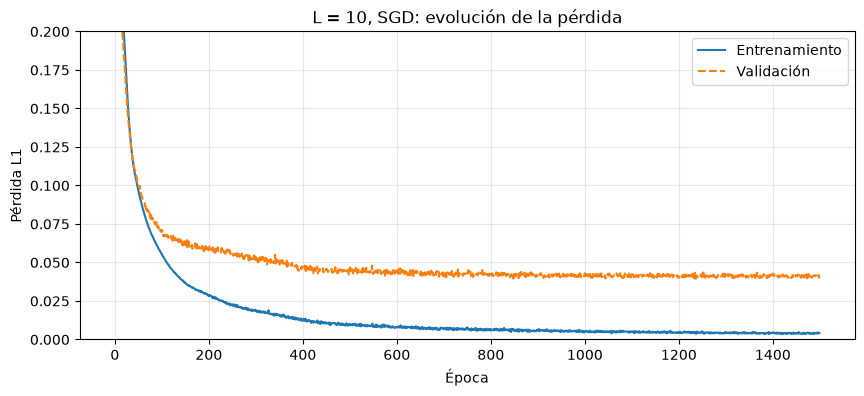

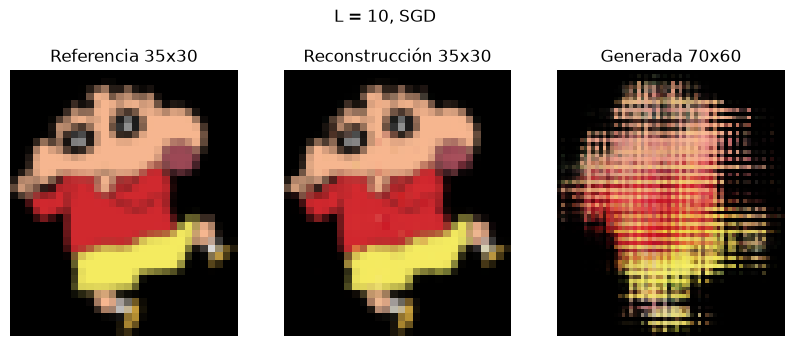

In [7]:
torch.manual_seed(SEED)
model_sgd = ImageMLP(n_freqs=10).to(device)
start = time.time()
hist_sgd, best_sgd = train_model(
    model_sgd, train_loader, val_loader, nn.L1Loss(),
    torch.optim.SGD(model_sgd.parameters(), lr=0.05), epochs=1500, log_every=300,
)
print(f"Tiempo: {time.time() - start:.1f} s | PSNR validación (última época): {psnr(model_sgd, val_loader):.2f} dB")
plot_history(hist_sgd, "L = 10, SGD: evolución de la pérdida")
show_renders(model_sgd, "L = 10, SGD")

### Diagnóstico: aliasing, no número de épocas

La reconstrucción a $35 \times 30$ es casi perfecta, pero la imagen a $70 \times 60$ muestra un patrón de rejilla. Las curvas dan la pista: la pérdida de entrenamiento tiende a cero mientras la de validación se estanca en un valor unas diez veces mayor. La red acierta en los píxeles que ha visto y falla **entre ellos**, justo donde se evalúa al duplicar la resolución.

Una primera hipótesis sería el sobreajuste por exceso de épocas, pero parar antes no lo resuelve: la validación no empeora, simplemente deja de mejorar. La causa está en la codificación:

- La imagen tiene 35 muestras en $[0, 1]$ a lo largo del eje vertical. Por el **teorema de muestreo de Nyquist**, la frecuencia más alta que esos datos pueden determinar es de unos $(35 - 1)/2 = 17$ ciclos por unidad.
- La banda $k$ de la codificación, $\sin(2^k \pi p)$, oscila a $2^{k-1}$ ciclos por unidad. Con $L = 10$ la última banda ($k = 9$) llega a **256 ciclos por unidad**, quince veces por encima del límite.

Con esas frecuencias la red puede pasar exactamente por los 1050 píxeles de entrenamiento con una función que oscila libremente entre ellos. Los datos no restringen esas oscilaciones, y aparecen como la rejilla de la imagen $70 \times 60$. Es el mismo fenómeno que el *aliasing* en procesamiento de señal.

La hipótesis es comprobable: si es correcta, limitar $L$ debería mejorar la validación y eliminar los artefactos, independientemente del optimizador.

## 6. Barrido de hiperparámetros sobre $L$

Se entrena el mismo modelo con distintos valores de $L$, todos con **Adam** (tasa de aprendizaje $10^{-3}$) y la misma semilla. Así se comprueban dos cosas a la vez: el efecto de $L$ y si el optimizador era parte del problema (el caso $L = 10$ con Adam lo responde). Cada ejecución se registra en una tabla, un primer ejemplo de **seguimiento de experimentos**.

Además de la validación, se dispone de una referencia que mide directamente el objetivo final: la imagen original es de $700 \times 600$, así que reducida a $70 \times 60$ da la **imagen real a doble resolución**. Se usa como conjunto de **test**, solo para evaluar y nunca para elegir hiperparámetros.

In [8]:
reference_2x = transforms.Resize((2 * IMG_H, 2 * IMG_W), antialias=True)(image_full).permute(1, 2, 0)


def psnr_image(img, ref):
    return 10 * math.log10(1 / ((img - ref) ** 2).mean().item())


print(f"PSNR 70x60 del experimento inicial (L = 10, SGD): {psnr_image(render(model_sgd, 2 * IMG_H, 2 * IMG_W), reference_2x):.2f} dB")

PSNR 70x60 del experimento inicial (L = 10, SGD): 12.73 dB


In [9]:
EPOCHS_SWEEP = 600
L_VALUES = [0, 2, 4, 6, 8, 10]

results, models = [], {}
for L in L_VALUES:
    torch.manual_seed(SEED)
    model = ImageMLP(n_freqs=L).to(device)
    start = time.time()
    hist, best = train_model(
        model, train_loader, val_loader, nn.L1Loss(),
        torch.optim.Adam(model.parameters(), lr=1e-3), epochs=EPOCHS_SWEEP,
    )
    model.load_state_dict(best["state"])
    models[L] = model
    results.append({
        "L": L,
        "frec. máx. (ciclos/u)": 2 ** (L - 2) if L > 0 else 0,
        "mejor época": best["epoch"],
        "L1 train": hist["train"][best["epoch"] - 1],
        "L1 val": best["val"],
        "PSNR val (dB)": psnr(model, val_loader),
        "PSNR test 70x60 (dB)": psnr_image(render(model, 2 * IMG_H, 2 * IMG_W), reference_2x),
        "tiempo (s)": time.time() - start,
    })
    print(f"L = {L:>2} | L1 val = {best['val']:.4f} | PSNR test 70x60 = {results[-1]['PSNR test 70x60 (dB)']:.2f} dB")

results_df = pd.DataFrame(results).set_index("L")
results_df.round(4)

L =  0 | L1 val = 0.0305 | PSNR test 70x60 = 19.48 dB


L =  2 | L1 val = 0.0274 | PSNR test 70x60 = 21.43 dB


L =  4 | L1 val = 0.0218 | PSNR test 70x60 = 21.63 dB


L =  6 | L1 val = 0.0288 | PSNR test 70x60 = 20.99 dB


L =  8 | L1 val = 0.0277 | PSNR test 70x60 = 14.13 dB


L = 10 | L1 val = 0.0265 | PSNR test 70x60 = 13.59 dB


,frec. máx. (ciclos/u),mejor época,L1 train,L1 val,PSNR val (dB),PSNR test 70x60 (dB),tiempo (s)
L,,,,,,,
0,0,571,0.0253,0.0305,23.2722,19.4843,57.7994
2,1,519,0.0107,0.0274,23.3206,21.4336,67.5058
4,4,188,0.0074,0.0218,26.6020,21.6315,67.3755
6,16,571,0.0034,0.0288,24.4197,20.9867,67.0359
8,64,310,0.0043,0.0277,23.7756,14.1264,82.2382
10,256,390,0.0037,0.0265,25.7371,13.5896,77.1027


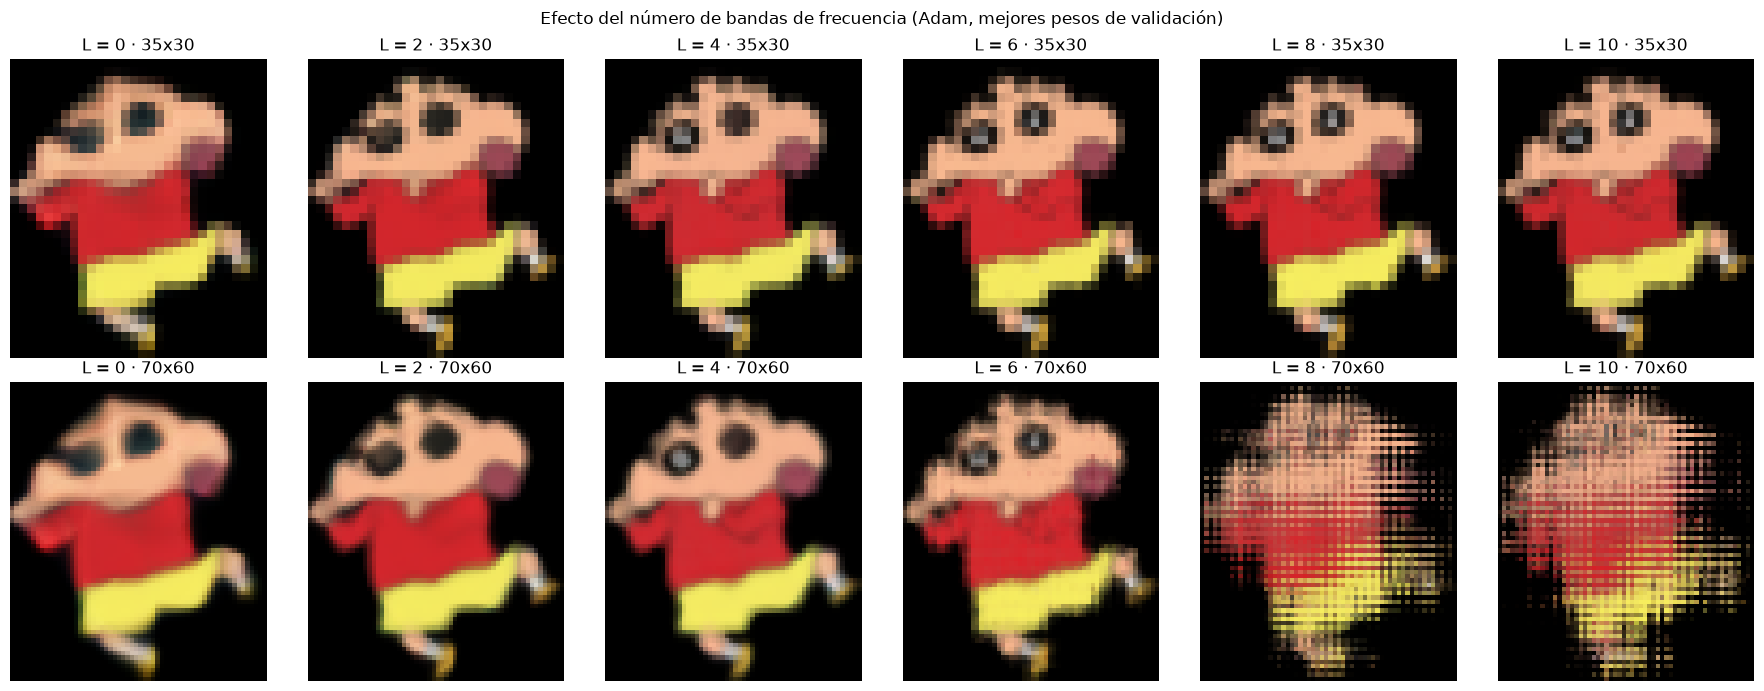

In [10]:
fig, axes = plt.subplots(2, len(L_VALUES), figsize=(3 * len(L_VALUES), 7))
for j, L in enumerate(L_VALUES):
    axes[0, j].imshow(render(models[L], IMG_H, IMG_W))
    axes[0, j].set_title(f"L = {L} · 35x30")
    axes[1, j].imshow(render(models[L], 2 * IMG_H, 2 * IMG_W))
    axes[1, j].set_title(f"L = {L} · 70x60")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Efecto del número de bandas de frecuencia (Adam, mejores pesos de validación)")
plt.tight_layout()
plt.show()

### Lectura del barrido

- **$L = 0$ (sin codificación)**: la imagen sale borrosa. Es el sesgo espectral en estado puro: la red solo aprende la forma general.
- **$L \le 6$**: las bandas no superan el límite de Nyquist (16 ciclos por unidad con $L = 6$, frente a unos 17 permitidos), y la imagen $70 \times 60$ es limpia.
- **$L = 8$ y $L = 10$**: la reconstrucción a $35 \times 30$ sigue siendo perfecta, pero a $70 \times 60$ reaparece la rejilla. Con **Adam y $L = 10$ el artefacto persiste**, así que el optimizador no era la causa.

Es un compromiso sesgo-varianza clásico, pero controlado por una etapa de **preprocesado** y no por el tamaño de la red: pocas frecuencias dan un modelo demasiado rígido; demasiadas le permiten memorizar la imagen.

### Una lección sobre el conjunto de validación

La tabla guarda una sorpresa. Por el error de validación, $L = 10$ **no parece peor** que $L = 6$ o $L = 8$, aunque sus imágenes $70 \times 60$ estén claramente estropeadas. Solo la columna de test a $70 \times 60$ refleja lo que se ve.

La explicación es el propio aliasing. Los píxeles de validación están sobre **la misma rejilla** de $35 \times 30$ que los de entrenamiento. Evaluada solo en esos puntos, una sinusoide de frecuencia muy alta es indistinguible de otra de frecuencia baja (su *alias*), así que la red interpola bien entre píxeles de la rejilla y el error de validación no detecta nada. Los artefactos aparecen **fuera** de la rejilla, justo donde la validación no mira.

Es una lección general de pipeline: **el conjunto de validación debe reproducir las condiciones de uso real**. Si el modelo se va a evaluar en posiciones nuevas, validar solo en la rejilla original da una estimación engañosa. Aquí la selección por validación acierta con el mejor valor, pero ordena mal los restantes; con otra semilla podría haberse equivocado.

## 7. Selección y reentrenamiento final

Se elige el $L$ con menor error de validación. La validación ya ha cumplido su función, que era elegir hiperparámetros, así que el modelo final se entrena con **todos los píxeles** durante el número de épocas en que ese modelo alcanzó su mejor validación. Es la práctica habitual en un pipeline: la partición sirve para decidir y el modelo desplegado aprovecha todos los datos.

La calidad final se mide con la referencia de test a $70 \times 60$ y se genera también una versión $\times 4$ ($140 \times 120$).

L seleccionado: 4 | épocas de reentrenamiento: 188


PSNR test 70x60 del modelo final: 21.61 dB


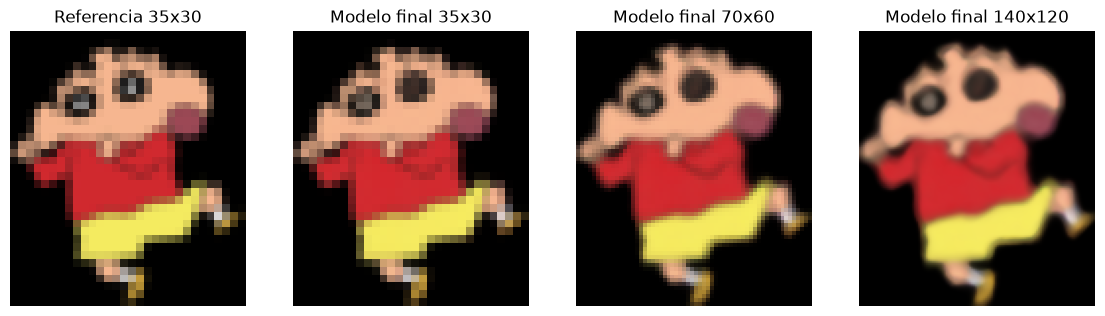

In [11]:
best_L = int(results_df["L1 val"].idxmin())
final_epochs = int(results_df.loc[best_L, "mejor época"])
print(f"L seleccionado: {best_L} | épocas de reentrenamiento: {final_epochs}")

full_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
torch.manual_seed(SEED)
final_model = ImageMLP(n_freqs=best_L).to(device)
optimizer = torch.optim.Adam(final_model.parameters(), lr=1e-3)
for _ in range(final_epochs):
    run_epoch(final_model, full_loader, nn.L1Loss(), optimizer)
print(f"PSNR test 70x60 del modelo final: {psnr_image(render(final_model, 2 * IMG_H, 2 * IMG_W), reference_2x):.2f} dB")

fig, axes = plt.subplots(1, 4, figsize=(14, 4.5))
panels = [
    (image_small.permute(1, 2, 0), "Referencia 35x30"),
    (render(final_model, IMG_H, IMG_W), "Modelo final 35x30"),
    (render(final_model, 2 * IMG_H, 2 * IMG_W), "Modelo final 70x60"),
    (render(final_model, 4 * IMG_H, 4 * IMG_W), "Modelo final 140x120"),
]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 8. Conclusiones

- **La representación de la entrada decide qué puede aprender la red.** El mismo MLP pasa de una imagen borrosa ($L = 0$) a una reconstrucción nítida o a una llena de artefactos cambiando solo la codificación de las coordenadas.
- **Los artefactos a doble resolución eran aliasing.** Las bandas de frecuencia por encima del límite de Nyquist de la imagen permiten a la red memorizar los píxeles y oscilar libremente entre ellos. Reducir las épocas o cambiar el optimizador no lo corrige; limitar $L$ sí.
- **La validación debe parecerse al uso real.** Validar con píxeles no vistos pero situados en la misma rejilla no detecta el aliasing, que solo aparece entre posiciones de la rejilla. Una referencia a $70 \times 60$ mide directamente el objetivo.
- **Un barrido registrado es mejor que la intuición.** Probar varias configuraciones con la misma semilla y apuntar los resultados convirtió una hipótesis en una conclusión comprobada.
- **Superresolución con límites.** La red interpola de forma suave y coherente, pero no puede inventar detalle que no estaba en los $35 \times 30$ píxeles de partida: la imagen $140 \times 120$ es más lisa, no más detallada.

**Siguiente paso:** en el cuaderno 03 se pasa de regresión a **clasificación** con un conjunto de datos real (CIFAR-10), se automatiza la parada del entrenamiento con *early stopping* y se mide el impacto del hardware (CPU frente a GPU).